In [1]:
!gdown --id 1eHChVwaAwG66p9eDhISOROPIvKXnMg9W

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1eHChVwaAwG66p9eDhISOROPIvKXnMg9W
From (redirected): https://drive.google.com/uc?id=1eHChVwaAwG66p9eDhISOROPIvKXnMg9W&confirm=t&uuid=6515f185-f42f-4b5c-a202-d893b2454a2e
To: /content/Arjun_Assignment_data-20220427T165022Z-002.zip
100% 1.67G/1.67G [00:15<00:00, 105MB/s] 


In [2]:
!unzip -l "/content/Arjun_Assignment_data-20220427T165022Z-002.zip" | head -40

Archive:  /content/Arjun_Assignment_data-20220427T165022Z-002.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
530146882  2021-06-09 05:31   Arjun_Assignment_data/dataset-20210607T020316Z-002.zip
580623450  2021-06-09 05:29   Arjun_Assignment_data/dataset-20210607T020316Z-003.zip
555854875  2021-06-09 00:47   Arjun_Assignment_data/dataset-20210607T020316Z-001.zip
---------                     -------
1666625207                     3 files


In [3]:
!unzip -q "/content/Arjun_Assignment_data-20220427T165022Z-002.zip" -d /content/assignment_archives
!ls -lh "/content/assignment_archives/Arjun_Assignment_data"

total 1.6G
-rw-r--r-- 1 root root 531M Jun  9  2021 dataset-20210607T020316Z-001.zip
-rw-r--r-- 1 root root 506M Jun  9  2021 dataset-20210607T020316Z-002.zip
-rw-r--r-- 1 root root 554M Jun  9  2021 dataset-20210607T020316Z-003.zip


In [4]:
!mkdir -p /content/data

!unzip -p "/content/assignment_archives/Arjun_Assignment_data/dataset-20210607T020316Z-001.zip" "dataset/posts_short.csv" > /content/data/posts_short.csv
!unzip -p "/content/assignment_archives/Arjun_Assignment_data/dataset-20210607T020316Z-001.zip" "dataset/postLinks.csv" > /content/data/postLinks.csv
!unzip -p "/content/assignment_archives/Arjun_Assignment_data/dataset-20210607T020316Z-002.zip" "dataset/users.csv" > /content/data/users.csv
!unzip -p "/content/assignment_archives/Arjun_Assignment_data/dataset-20210607T020316Z-003.zip" "dataset/post_history.csv" > /content/data/post_history.csv

!ls -lh /content/data

total 3.0G
-rw-r--r-- 1 root root 2.0G Oct 24 08:41 post_history.csv
-rw-r--r-- 1 root root 311M Oct 24 08:41 postLinks.csv
-rw-r--r-- 1 root root  66M Oct 24 08:41 posts_short.csv
-rw-r--r-- 1 root root 604M Oct 24 08:41 users.csv


In [5]:
import glob
import zipfile
import pandas as pd

zip_files = glob.glob(
    "/content/assignment_archives/Arjun_Assignment_data/*.zip"
)

for zip_path in sorted(zip_files):
    print(f"\nZIP: {zip_path}")

    with zipfile.ZipFile(zip_path) as archive:
        for file_name in archive.namelist():
            if file_name.lower().endswith(".csv"):
                with archive.open(file_name) as file:
                    columns = pd.read_csv(file, nrows=0).columns.tolist()

                print(f"\n{file_name}")
                for column in columns:
                    print("-", column)


ZIP: /content/assignment_archives/Arjun_Assignment_data/dataset-20210607T020316Z-001.zip

dataset/posts_short.csv
- Unnamed: 0
- id
- post_type_id
- accepted_answer_id
- parent_id
- creation_date
- score
- view_count
- owner_user_id
- tags
- answer_count
- comment_count
- favorite_count
- community_owned_date

dataset/postLinks.csv
- Unnamed: 0
- id
- creation_date
- post_id
- related_post_id
- link_type_id

dataset/posts_long.csv
- Unnamed: 0
- id
- post_type_id
- accepted_answer_id
- parent_id
- creation_date
- score
- view_count
- owner_user_id
- tags
- answer_count
- comment_count
- favorite_count
- community_owned_date
- title
- body

ZIP: /content/assignment_archives/Arjun_Assignment_data/dataset-20210607T020316Z-002.zip

dataset/users.csv
- Unnamed: 0
- id
- reputation
- creation_date
- display_name
- views
- upvotes
- downvotes
- account_id

ZIP: /content/assignment_archives/Arjun_Assignment_data/dataset-20210607T020316Z-003.zip

dataset/post_history.csv
- Unnamed: 0
- id
- ph

##Q-1 Determine the Number of Tags Per Question


In [84]:
import pandas as pd
import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

In [12]:
# Load the post ID, post type, and tags
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "tags"]
)

# Keep questions only
questions = posts[posts["post_type_id"] == 1].copy()

# Count the tags for each question
questions["number_of_tags"] = questions["tags"].apply(
    lambda tags: len(re.findall(r"<([^>]+)>", tags))
    if isinstance(tags, str) else 0
)

In [13]:
# Create the frequency table BEFORE printing or plotting it
tag_frequency = (
    questions["number_of_tags"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_tags")
    .reset_index(name="number_of_questions")
)


In [14]:
# Save each question's tag count
questions[["id", "number_of_tags"]].rename(
    columns={"id": "question_id"}
).to_csv("/content/data/q1_tags_per_question.csv", index=False)

# Calculate and print the average and frequency table
average_tags = questions["number_of_tags"].mean()

print("Total questions:", len(questions))
print("Average tags per question:", round(average_tags, 2))
print("\nNumber of questions for each tag count:")
print(tag_frequency.to_string(index=False))

Total questions: 676204
Average tags per question: 2.84

Number of questions for each tag count:
 number_of_tags  number_of_questions
              1                94523
              2               189704
              3               194334
              4               124127
              5                73490
              6                   26


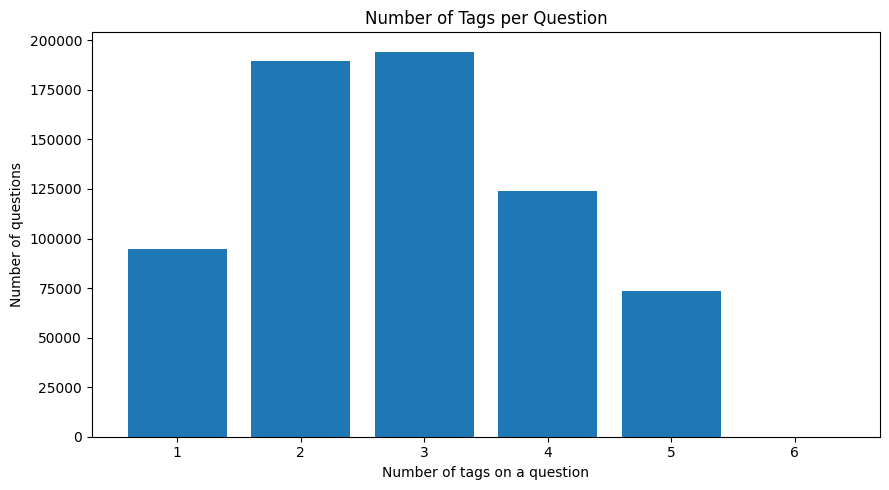

In [15]:
# Plot the frequency graph
plt.figure(figsize=(9, 5))
plt.bar(
    tag_frequency["number_of_tags"],
    tag_frequency["number_of_questions"]
)
plt.title("Number of Tags per Question")
plt.xlabel("Number of tags on a question")
plt.ylabel("Number of questions")
plt.xticks(tag_frequency["number_of_tags"])
plt.tight_layout()
plt.show()

##Q-2 Determine the Total Number of Unique Tags


In [16]:
# Load the post type and tags columns
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

In [17]:
questions = posts[posts["post_type_id"] == 1]


In [18]:
# Collect each tag in a set; sets keep only one copy of each tag
unique_tags = set()

for tag_text in questions["tags"].dropna():
    unique_tags.update(re.findall(r"<([^>]+)>", tag_text))

In [19]:
print("Total unique tags:", len(unique_tags))

Total unique tags: 25310


##Q-3 Determine the top-25 Tags appearing frequently

In [20]:
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

In [21]:
questions = posts[posts["post_type_id"] == 1]

tag_counts = Counter()

for tag_text in questions["tags"].dropna():
    tag_counts.update(re.findall(r"<([^>]+)>", tag_text))

top_25_tags = pd.DataFrame(
    tag_counts.most_common(25),
    columns=["Tag", "Number of appearances"]
)

In [22]:
display(top_25_tags)

,Tag,Number of appearances
0,java,94846
1,javascript,81346
2,php,65333
3,c#,61899
4,python,61505
5,c++,40158
6,android,39910
7,html,33736
8,jquery,32601
9,mysql,24765


##Q-4 Determine the nature of the distribution of top-500 tags

In [23]:
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

In [24]:
questions = posts[posts["post_type_id"] == 1]

tag_counts = Counter()


In [25]:
for tag_text in questions["tags"].dropna():
    tag_counts.update(re.findall(r"<([^>]+)>", tag_text))

top_500_frequencies = [
    count for tag, count in tag_counts.most_common(500)
]

frequencies = pd.Series(top_500_frequencies)


In [26]:
print("Number of tags analyzed:", len(frequencies))
print("Mean frequency:", round(frequencies.mean(), 2))
print("Median frequency:", round(frequencies.median(), 2))
print("Skewness:", round(frequencies.skew(), 2))

Number of tags analyzed: 500
Mean frequency: 2886.76
Median frequency: 978.0
Skewness: 7.28


##Q-5 Determine the ratio of duplicate questions asked in each month

In [28]:
# Load link type and post ID from the links file
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id"]
)

In [29]:
# Link type 3 identifies duplicate-question links.
# Keep each duplicate question ID only once.
duplicate_ids = links.loc[
    links["link_type_id"] == 3, "post_id"
].drop_duplicates()


In [30]:
# Load question IDs, post types, and creation dates
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "creation_date"]
)

In [31]:
# Keep questions and convert their dates
questions = posts[posts["post_type_id"] == 1].copy()
questions["creation_date"] = pd.to_datetime(
    questions["creation_date"], errors="coerce"
)

In [32]:
# Keep questions asked from 2008 through 2018
questions = questions[
    (questions["creation_date"] >= "2008-01-01") &
    (questions["creation_date"] < "2019-01-01")
].copy()

In [33]:
# Assign each question to the month it was asked
questions["month"] = questions["creation_date"].dt.to_period("M")

# Include every month from January 2008 through December 2018
months = pd.period_range("2008-01", "2018-12", freq="M")


In [34]:
# Count all questions in each month
total_questions = (
    questions.groupby("month")
    .size()
    .reindex(months, fill_value=0)
)

# Count duplicate questions in each month
duplicate_questions = (
    questions[questions["id"].isin(duplicate_ids)]
    .groupby("month")
    .size()
    .reindex(months, fill_value=0)
)

In [35]:
# Calculate the percentage of questions that are duplicates
monthly_ratio = (
    duplicate_questions
    / total_questions.where(total_questions != 0)
    * 100
).fillna(0)

# Display the monthly results
monthly_results = pd.DataFrame({
    "total_questions": total_questions,
    "duplicate_questions": duplicate_questions,
    "duplicate_ratio_percent": monthly_ratio
})
print(monthly_results)

         total_questions  duplicate_questions  duplicate_ratio_percent
2008-01                0                    0                 0.000000
2008-02                0                    0                 0.000000
2008-03                0                    0                 0.000000
2008-04                0                    0                 0.000000
2008-05                0                    0                 0.000000
...                  ...                  ...                      ...
2018-08             9227                 8910                96.564430
2018-09              179                  176                98.324022
2018-10                0                    0                 0.000000
2018-11                0                    0                 0.000000
2018-12                0                    0                 0.000000

[132 rows x 3 columns]


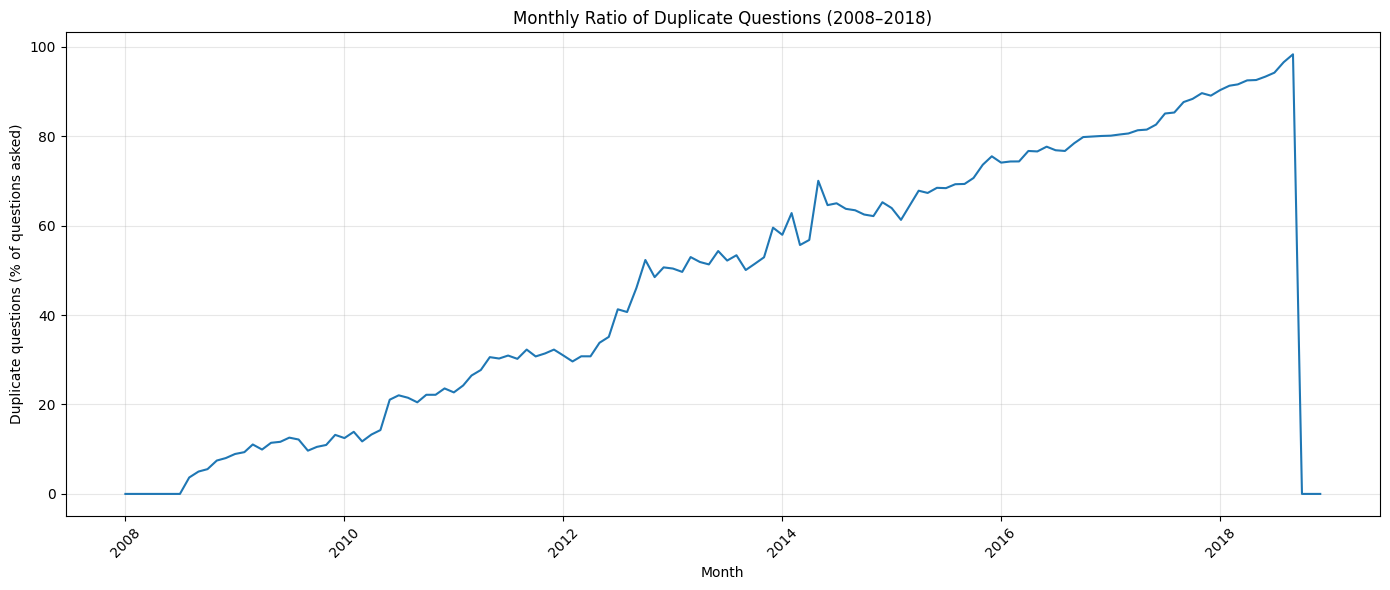

In [36]:
#line graph
monthly_ratio.index = monthly_ratio.index.to_timestamp()

plt.figure(figsize=(14, 6))
plt.plot(monthly_ratio.index, monthly_ratio.values)
plt.title("Monthly Ratio of Duplicate Questions (2008–2018)")
plt.xlabel("Month")
plt.ylabel("Duplicate questions (% of questions asked)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Q-6 Determine the percentage of duplicate questions associated with different tags

In [37]:
# Load post links and identify duplicate-question IDs
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id"]
)

duplicate_ids = set(
    links.loc[links["link_type_id"] == 3, "post_id"].dropna()
)
# Load post IDs, post types, and tags
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "tags"]
)


In [38]:
# Keep questions only
questions = posts[posts["post_type_id"] == 1].copy()
questions["is_duplicate"] = questions["id"].isin(duplicate_ids)

In [39]:
# Count questions and duplicate questions for each tag
total_by_tag = Counter()
duplicate_by_tag = Counter()

for tags, is_duplicate in zip(
    questions["tags"].fillna(""),
    questions["is_duplicate"]
):
    # Extract tags from text such as <python><pandas>
    question_tags = set(re.findall(r"<([^>]+)>", tags))

    for tag in question_tags:
        total_by_tag[tag] += 1

        if is_duplicate:
            duplicate_by_tag[tag] += 1


In [40]:
# Create a table for all tags
tag_results = pd.DataFrame({
    "tag": list(total_by_tag.keys()),
    "total_questions": [
        total_by_tag[tag] for tag in total_by_tag
    ],
    "duplicate_questions": [
        duplicate_by_tag[tag] for tag in total_by_tag
    ]
})

In [41]:
# Calculate the duplicate-question percentage for each tag
tag_results["duplicate_percentage"] = (
    tag_results["duplicate_questions"]
    / tag_results["total_questions"]
    * 100
)

In [42]:
# Select the 20 tags with the most duplicate questions
top_20_tags = tag_results.sort_values(
    "duplicate_questions",
    ascending=False
).head(20)

# Display the results
print(top_20_tags.to_string(index=False))

# Save results for all tags
tag_results.to_csv(
    "/content/data/q6_duplicate_percentage_by_tag.csv",
    index=False
)

        tag  total_questions  duplicate_questions  duplicate_percentage
       java            94846                59498             62.731164
 javascript            81346                56178             69.060556
        php            65333                44619             68.294736
     python            61505                38427             62.477847
         c#            61899                35913             58.018708
        c++            40158                25037             62.346232
       html            33736                23282             69.012331
    android            39910                22987             57.597093
     jquery            32601                21293             65.313947
      mysql            24765                16641             67.195639
        css            23161                15357             66.305427
     arrays            19867                13471             67.805909
          c            22166                13449             60

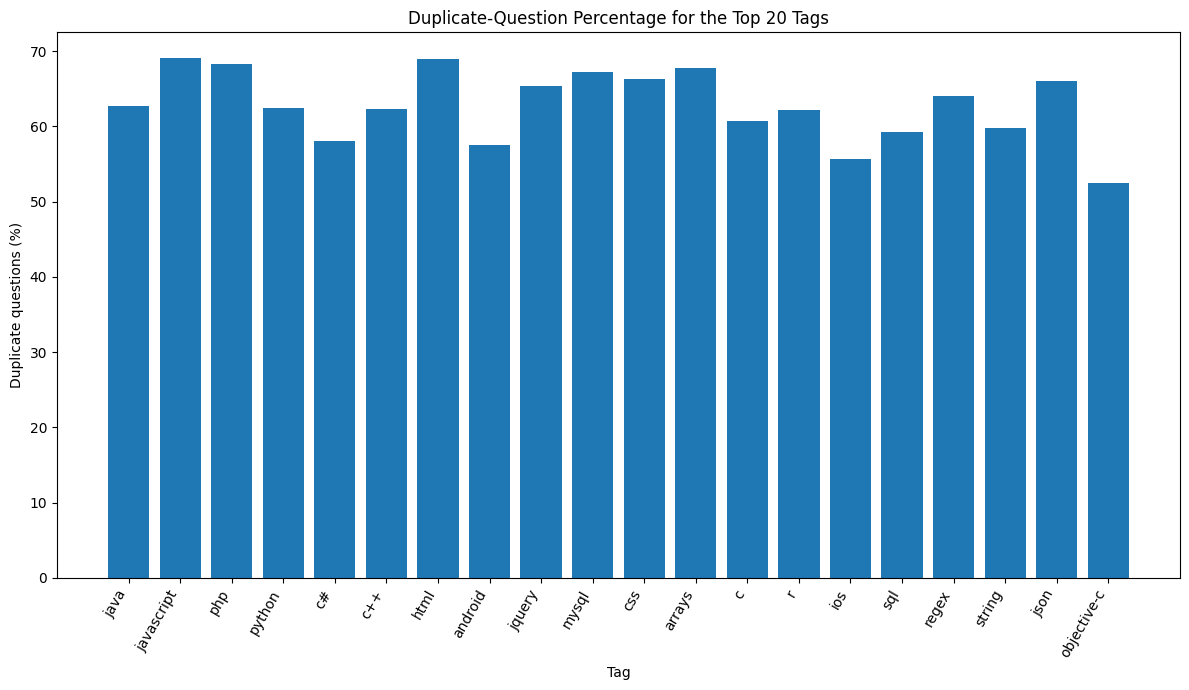

In [43]:

# Plot the duplicate percentage for the top 20 tags
plt.figure(figsize=(12, 7))
plt.bar(
    top_20_tags["tag"],
    top_20_tags["duplicate_percentage"]
)
plt.title("Duplicate-Question Percentage for the Top 20 Tags")
plt.xlabel("Tag")
plt.ylabel("Duplicate questions (%)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

##Q-7	Determine the time required to close duplicate questions


In [44]:
# Get IDs of duplicate questions
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id"]
)

duplicate_ids = set(
    links.loc[links["link_type_id"] == 3, "post_id"].dropna()
)

In [45]:
# Get the creation date of each duplicate question
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "creation_date"]
)

questions = posts[
    (posts["post_type_id"] == 1) &
    (posts["id"].isin(duplicate_ids))
].copy()

questions["creation_date"] = pd.to_datetime(
    questions["creation_date"], errors="coerce"
)


In [46]:
# Read post history in chunks because the file is large.
# Find history records marking a question's duplicate closure.
close_events = []

for chunk in pd.read_csv(
    "/content/data/post_history.csv",
    usecols=["ph_type_id", "post_id", "creation_date", "comment"],
    chunksize=500_000,
    dtype={"ph_type_id": "Int64", "post_id": "Int64"}
):
    duplicate_close = (
        (chunk["ph_type_id"] == 10) &
        (chunk["post_id"].isin(duplicate_ids)) &
        (chunk["comment"].astype("string").str.strip().isin(["1", "101"]))
    )

    close_events.append(
        chunk.loc[duplicate_close, ["post_id", "creation_date"]]
    )

close_events = pd.concat(close_events, ignore_index=True)
close_events["creation_date"] = pd.to_datetime(
    close_events["creation_date"], errors="coerce"
)

In [47]:
# Use the first recorded duplicate-closure date for each question
first_close = (
    close_events.dropna(subset=["creation_date"])
    .groupby("post_id")["creation_date"]
    .min()
    .reset_index(name="close_date")
)


In [48]:
# Calculate time from question creation to closure, in hours
results = questions.merge(
    first_close,
    left_on="id",
    right_on="post_id",
    how="inner"
)

results["hours_to_close"] = (
    results["close_date"] - results["creation_date"]
).dt.total_seconds() / 3600

results = results[results["hours_to_close"] >= 0].copy()


In [49]:
# Group durations so they can be shown clearly in a bar chart
bins = [0, 1, 24, 168, 720, float("inf")]
labels = ["Up to 1 hour", "1–24 hours", "1–7 days", "7–30 days", "Over 30 days"]

results["time_range"] = pd.cut(
    results["hours_to_close"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

counts = results["time_range"].value_counts(sort=False)


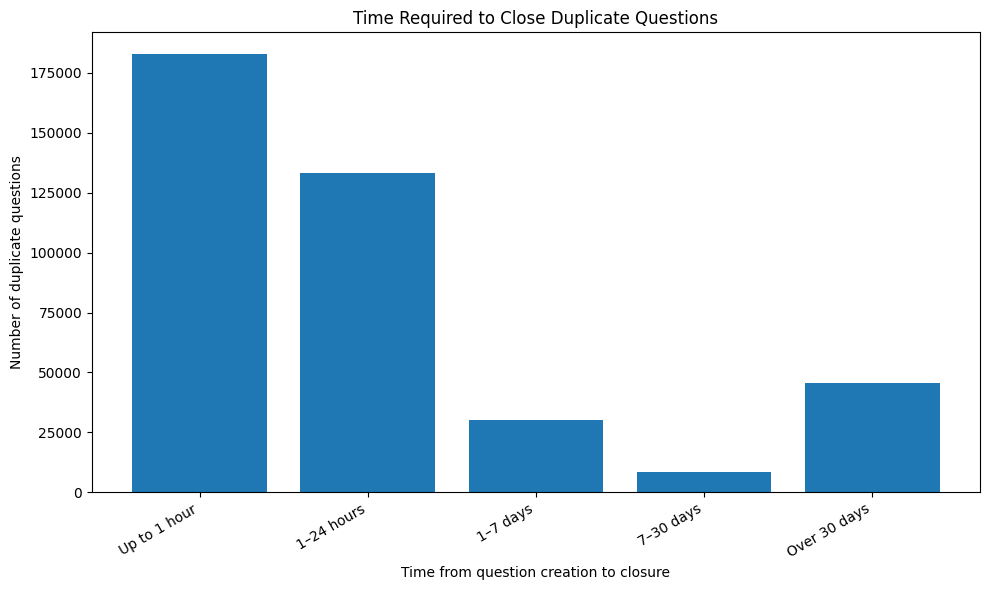

In [50]:
# bar chart
plt.figure(figsize=(10, 6))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Time Required to Close Duplicate Questions")
plt.xlabel("Time from question creation to closure")
plt.ylabel("Number of duplicate questions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##Q-8 Distribution of the reputation of users whose questions are closed as duplicates

In [51]:
# Find IDs of duplicate questions
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id"]
)

duplicate_ids = set(
    links.loc[links["link_type_id"] == 3, "post_id"].dropna()
)

In [52]:
# Find the users who asked those duplicate questions
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "owner_user_id"]
)

duplicate_questions = posts[
    (posts["post_type_id"] == 1) &
    (posts["id"].isin(duplicate_ids))
]

In [53]:
# Keep each identifiable asker only once
asker_ids = set(
    pd.to_numeric(
        duplicate_questions["owner_user_id"],
        errors="coerce"
    ).dropna().astype("int64")
)

In [54]:
# Read users.csv in chunks and collect the matching users' reputations
user_parts = []

for chunk in pd.read_csv(
    "/content/data/users.csv",
    usecols=["id", "reputation"],
    chunksize=500_000
):
    chunk["id"] = pd.to_numeric(chunk["id"], errors="coerce")

    matching_users = chunk[chunk["id"].isin(asker_ids)]
    user_parts.append(matching_users)

users_with_reputation = pd.concat(user_parts, ignore_index=True)


In [55]:
# Remove missing reputations and count each user only once
users_with_reputation["reputation"] = pd.to_numeric(
    users_with_reputation["reputation"],
    errors="coerce"
)

users_with_reputation = (
    users_with_reputation
    .dropna(subset=["id", "reputation"])
    .drop_duplicates(subset="id")
)

In [56]:
# Group reputation into ranges
bins = [-float("inf"), 100, 500, 1000, 5000, 10000, float("inf")]
labels = [
    "0–100",
    "101–500",
    "501–1,000",
    "1,001–5,000",
    "5,001–10,000",
    "Over 10,000"
]

users_with_reputation["reputation_range"] = pd.cut(
    users_with_reputation["reputation"],
    bins=bins,
    labels=labels
)

In [57]:
# Count users in each reputation range
user_counts = (
    users_with_reputation["reputation_range"]
    .value_counts(sort=False)
    .reindex(labels, fill_value=0)
)

print("Number of unique duplicate-question askers in each reputation range:")
print(user_counts)

Number of unique duplicate-question askers in each reputation range:
reputation_range
0–100           172586
101–500          53682
501–1,000        20785
1,001–5,000      27598
5,001–10,000      5228
Over 10,000       4732
Name: count, dtype: int64


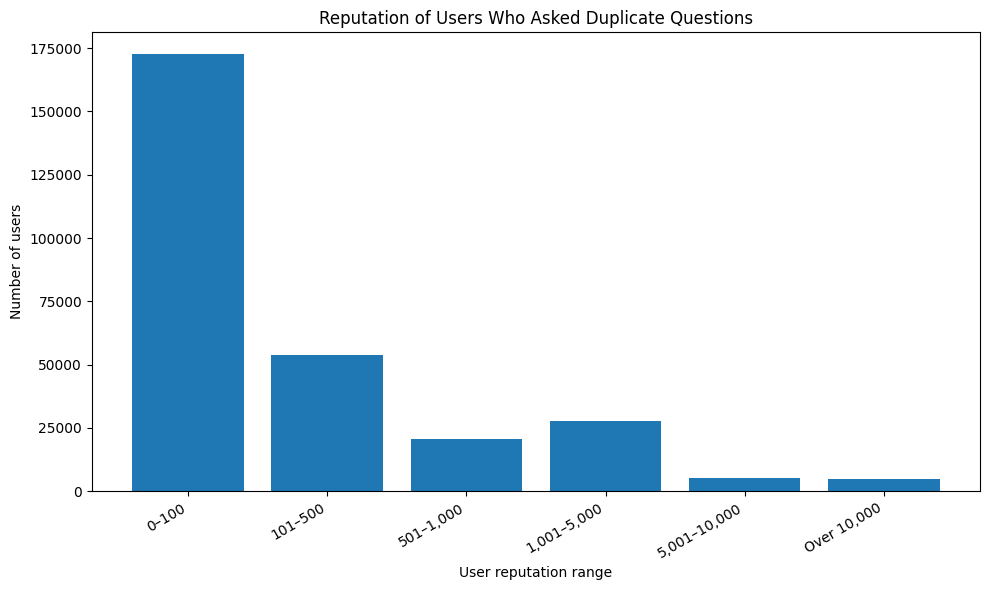

In [58]:
# Generate the required bar chart
plt.figure(figsize=(10, 6))
plt.bar(user_counts.index.astype(str), user_counts.values)
plt.title("Reputation of Users Who Asked Duplicate Questions")
plt.xlabel("User reputation range")
plt.ylabel("Number of users")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##Q-9	Consider the first 500 tags and determine how many percentage of questions are been covered

In [59]:
# Load post type and tags
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

In [60]:
# Keep questions
questions = posts[posts["post_type_id"] == 1].copy()

# Extract tags from each question
question_tags = [
    set(re.findall(r"<([^>]+)>", tags))
    for tags in questions["tags"].fillna("")
]

In [61]:
# Count how often each tag appears across questions
tag_frequency = Counter()

for tags in question_tags:
    tag_frequency.update(tags)

# Select the 500 most frequent tags
top_500_tags = {
    tag for tag, count in tag_frequency.most_common(500)
}


In [62]:
# Count questions that have at least one of the top 500 tags
covered_questions = sum(
    bool(tags & top_500_tags)
    for tags in question_tags
)

total_questions = len(questions)
coverage_percentage = covered_questions / total_questions * 100

print("Total questions:", total_questions)
print("Questions covered by the top 500 tags:", covered_questions)
print("Percentage of questions covered:", round(coverage_percentage, 2), "%")

Total questions: 676204
Questions covered by the top 500 tags: 662549
Percentage of questions covered: 97.98 %


##Q-10  Repeat Q.9 for first 5000 tags

In [63]:
# Load post type and tags
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

In [64]:
# Keep questions
questions = posts[posts["post_type_id"] == 1].copy()

# Extract tags from each question
question_tags = [
    set(re.findall(r"<([^>]+)>", tags))
    for tags in questions["tags"].fillna("")
]

In [65]:
# Count how often each tag appears
tag_frequency = Counter()

for tags in question_tags:
    tag_frequency.update(tags)

# Select the 5,000 most frequent tags
top_5000_tags = {
    tag for tag, count in tag_frequency.most_common(5000)
}

In [66]:
# Count questions containing at least one of those tags
covered_questions = sum(
    bool(tags & top_5000_tags)
    for tags in question_tags
)

total_questions = len(questions)
coverage_percentage = covered_questions / total_questions * 100

print("Total questions:", total_questions)
print("Questions covered by the top 5000 tags:", covered_questions)
print("Percentage of questions covered:", round(coverage_percentage, 2), "%")

Total questions: 676204
Questions covered by the top 5000 tags: 675145
Percentage of questions covered: 99.84 %


###What percentage of questions are duplicates, and what percentage are not?

In [67]:
# Get IDs of questions marked as duplicates
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id"]
)

duplicate_ids = set(
    links.loc[links["link_type_id"] == 3, "post_id"].dropna()
)


In [68]:
# Load posts and keep questions only
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id"]
)

questions = posts[posts["post_type_id"] == 1].copy()


In [70]:
# Mark each question as duplicate or non-duplicate
questions["status"] = questions["id"].isin(duplicate_ids).map({
    True: "Duplicate",
    False: "Non-duplicate"
})

# Count questions in each group and calculate percentages
counts = questions["status"].value_counts().reindex(
    ["Duplicate", "Non-duplicate"],
    fill_value=0
)
percentages = counts / counts.sum() * 100
print("Question counts:")
print(counts)
print("\nQuestion percentages:")
print(percentages.round(2))

Question counts:
status
Duplicate        399974
Non-duplicate    276230
Name: count, dtype: int64

Question percentages:
status
Duplicate        59.15
Non-duplicate    40.85
Name: count, dtype: float64


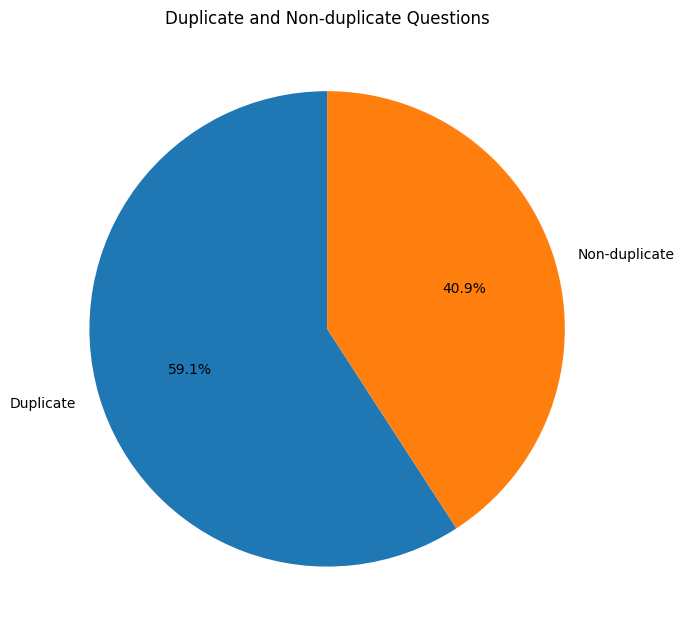

In [71]:
# Create the pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    counts,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Duplicate and Non-duplicate Questions")
plt.tight_layout()
plt.show()

##How did the numbers of duplicate and non-duplicate questions change each year from 2008 to 2018?


In [72]:
# Identify duplicate question IDs
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id"]
)

duplicate_ids = set(
    links.loc[links["link_type_id"] == 3, "post_id"].dropna()
)

In [73]:
# Load question IDs, types, and creation dates
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "creation_date"]
)

In [74]:
# Keep questions only and prepare their dates
questions = posts[posts["post_type_id"] == 1].copy()
questions["creation_date"] = pd.to_datetime(
    questions["creation_date"], errors="coerce"
)
questions = questions.dropna(subset=["creation_date"])


In [75]:
# Keep questions from 2008 through 2018
questions = questions[
    (questions["creation_date"] >= "2008-01-01") &
    (questions["creation_date"] < "2019-01-01")
].copy()

questions["year"] = questions["creation_date"].dt.year

In [76]:
# Label each question as duplicate or non-duplicate
questions["status"] = questions["id"].isin(duplicate_ids).map({
    True: "Duplicate",
    False: "Non-duplicate"
})

In [77]:
# Count both groups in each year
yearly_counts = (
    questions.groupby(["year", "status"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(2008, 2019), fill_value=0)
)

print(yearly_counts)

status  Duplicate  Non-duplicate
year                            
2008          497           7811
2009         2893          23248
2010         7364          32319
2011        17059          41345
2012        27764          41385
2013        43243          39123
2014        47768          28554
2015        54266          24825
2016        65651          19543
2017        73914          13503
2018        59555           4574


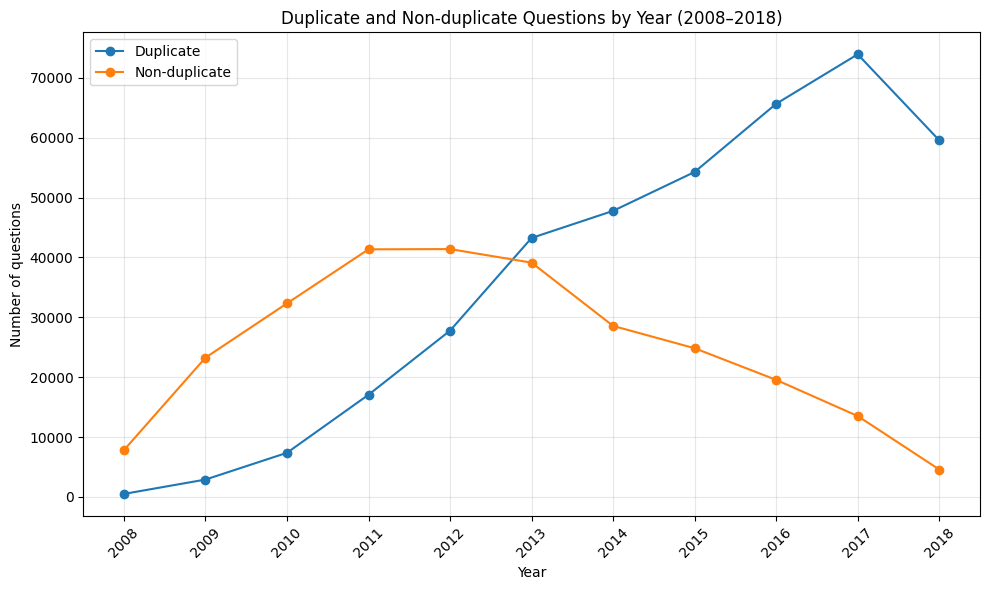

In [78]:
# Plot the two yearly counts as lines
plt.figure(figsize=(10, 6))
plt.plot(
    yearly_counts.index,
    yearly_counts["Duplicate"],
    marker="o",
    label="Duplicate"
)
plt.plot(
    yearly_counts.index,
    yearly_counts["Non-duplicate"],
    marker="o",
    label="Non-duplicate"
)

plt.title("Duplicate and Non-duplicate Questions by Year (2008–2018)")
plt.xlabel("Year")
plt.ylabel("Number of questions")
plt.xticks(range(2008, 2019), rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##How long did duplicate questions take to close, and which closure times were most common?

In [79]:
# Load duplicate links and their creation dates
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id", "creation_date"]
)

duplicate_links = links[links["link_type_id"] == 3].copy()
duplicate_links["creation_date"] = pd.to_datetime(
    duplicate_links["creation_date"],
    errors="coerce"
)

In [80]:

# Use the first duplicate-link date for each question
close_dates = (
    duplicate_links.dropna(subset=["creation_date"])
    .groupby("post_id")["creation_date"]
    .min()
    .reset_index(name="close_date")
)

# Load question IDs and creation dates
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "creation_date"]
)

questions = posts[posts["post_type_id"] == 1].copy()
questions["creation_date"] = pd.to_datetime(
    questions["creation_date"],
    errors="coerce"
)

In [81]:
# Match each duplicate question with its dates
results = questions.merge(
    close_dates,
    left_on="id",
    right_on="post_id",
    how="inner"
)

# Calculate the time from question creation to duplicate-link creation
results["days_to_close"] = (
    results["close_date"] - results["creation_date"]
).dt.total_seconds() / (60 * 60 * 24)

results = results[results["days_to_close"] >= 0].dropna(
    subset=["days_to_close"]
)

In [85]:
# Find the most common range in the histogram
bin_counts, bin_edges = np.histogram(results["days_to_close"], bins=30)
most_common_bin = bin_counts.argmax()

print(
    "Most common time range (days):",
    round(bin_edges[most_common_bin], 2),
    "to",
    round(bin_edges[most_common_bin + 1], 2)
)
print("Questions in that range:", bin_counts[most_common_bin])

Most common time range (days): 0.0 to 120.78
Questions in that range: 331920


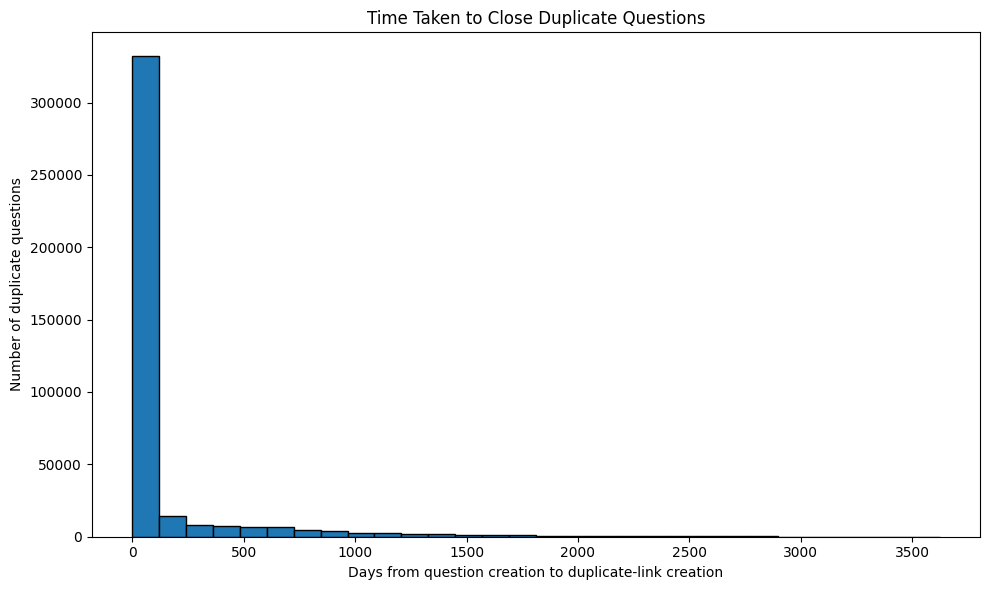

In [83]:
# Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(results["days_to_close"], bins=30, edgecolor="black")
plt.title("Time Taken to Close Duplicate Questions")
plt.xlabel("Days from question creation to duplicate-link creation")
plt.ylabel("Number of duplicate questions")
plt.tight_layout()
plt.show()

## Is there a relationship between a question’s number of views and its score?

In [86]:
# Load post type, views, and score
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["post_type_id", "view_count", "score"]
)

# Keep questions with both views and scores
questions = posts[posts["post_type_id"] == 1].copy()
questions["view_count"] = pd.to_numeric(
    questions["view_count"], errors="coerce"
)
questions["score"] = pd.to_numeric(
    questions["score"], errors="coerce"
)
questions = questions.dropna(subset=["view_count", "score"])

In [87]:
# Calculate the correlation using all valid questions
correlation = questions["view_count"].corr(questions["score"])
print("Number of questions analyzed:", len(questions))
print("Correlation between views and score:", round(correlation, 3))

# Use a sample to make the scatter plot easier to read
sample = questions.sample(
    n=min(20000, len(questions)),
    random_state=42
)


Number of questions analyzed: 676204
Correlation between views and score: 0.729


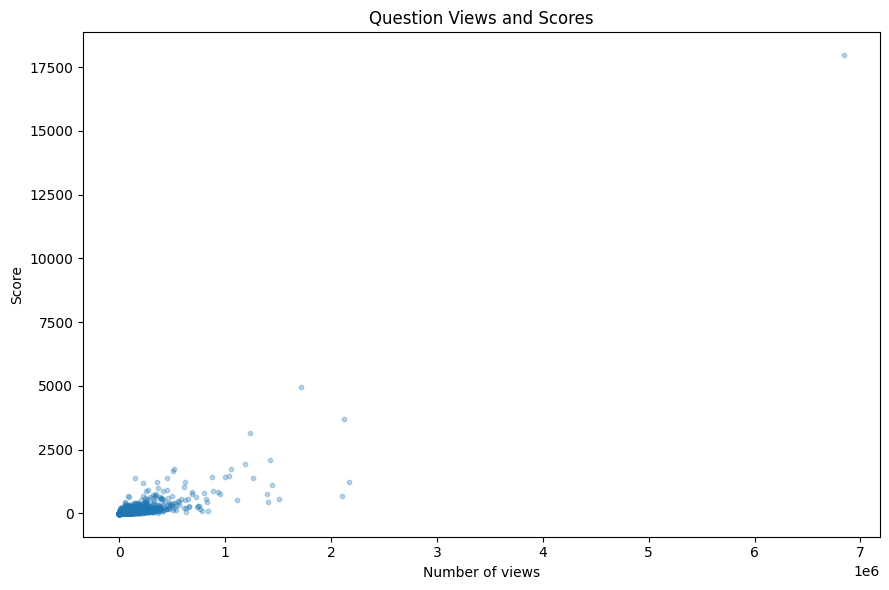

In [88]:
plt.figure(figsize=(9, 6))
plt.scatter(
    sample["view_count"],
    sample["score"],
    alpha=0.3,
    s=10
)
plt.title("Question Views and Scores")
plt.xlabel("Number of views")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

##How does the reputation of people who asked duplicate questions compare with the reputation of people who asked non-duplicate questions?

In [89]:
# Identify duplicate question IDs
links = pd.read_csv(
    "/content/data/postLinks.csv",
    usecols=["post_id", "link_type_id"]
)

duplicate_question_ids = set(
    links.loc[links["link_type_id"] == 3, "post_id"].dropna()
)


In [90]:
# Load questions and their askers
posts = pd.read_csv(
    "/content/data/posts_short.csv",
    usecols=["id", "post_type_id", "owner_user_id"]
)

questions = posts[posts["post_type_id"] == 1].copy()
questions["owner_user_id"] = pd.to_numeric(
    questions["owner_user_id"], errors="coerce"
)
questions = questions.dropna(subset=["owner_user_id"])


In [91]:
# Get unique asker IDs in each group
duplicate_askers = set(
    questions.loc[
        questions["id"].isin(duplicate_question_ids), "owner_user_id"
    ].astype("int64")
)

nonduplicate_askers = set(
    questions.loc[
        ~questions["id"].isin(duplicate_question_ids), "owner_user_id"
    ].astype("int64")
)

all_askers = duplicate_askers | nonduplicate_askers

In [92]:
# Read only matching users from the large users file, in chunks
user_parts = []

for chunk in pd.read_csv(
    "/content/data/users.csv",
    usecols=["id", "reputation"],
    chunksize=500_000
):
    chunk["id"] = pd.to_numeric(chunk["id"], errors="coerce")
    chunk["reputation"] = pd.to_numeric(
        chunk["reputation"], errors="coerce"
    )
    user_parts.append(chunk[chunk["id"].isin(all_askers)])

user_info = pd.concat(user_parts, ignore_index=True)
user_info = user_info.dropna(subset=["id", "reputation"])
user_info = user_info.drop_duplicates(subset="id")

# Get reputations for each group
duplicate_reputation = user_info.loc[
    user_info["id"].isin(duplicate_askers), "reputation"
]

nonduplicate_reputation = user_info.loc[
    user_info["id"].isin(nonduplicate_askers), "reputation"
]

/tmp/ipykernel_537/754226671.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


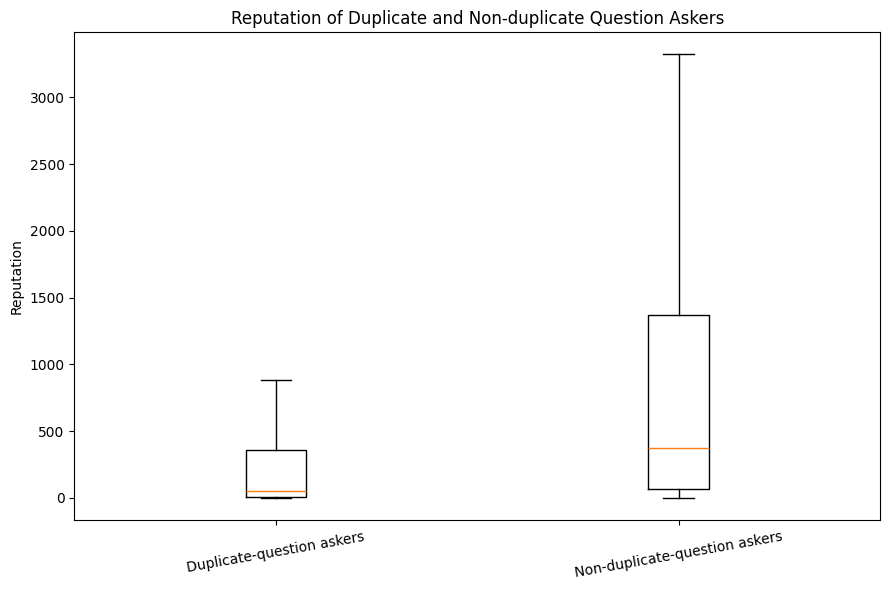

In [93]:
# Compare the two reputation distributions with a box plot
plt.figure(figsize=(9, 6))
plt.boxplot(
    [duplicate_reputation, nonduplicate_reputation],
    labels=["Duplicate-question askers", "Non-duplicate-question askers"],
    showfliers=False
)
plt.title("Reputation of Duplicate and Non-duplicate Question Askers")
plt.ylabel("Reputation")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()